#Phase 2: Data Collection, Exploration & Preprocessing
**Sentiment and Emotion Detection in Roman Urdu–English Code-Switched Text**

· Eman Faisal · Mahnoor Fatima · Khadija Faiz

## 0. Setup

In [ ]:
import os, re, json, html, sys, subprocess
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
try:
    import emoji
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "emoji"])
    import emoji

SEED = 42
np.random.seed(SEED)
OUT, FIG = "data/processed", "figures"
os.makedirs(OUT, exist_ok=True)
os.makedirs(FIG, exist_ok=True)
sns.set_theme(style="whitegrid")

S = {}   # running summary of key numbers, saved at the end and used in the report

## 1. Data collection and loading
**Source:** *Emotions Lexicons in Roman Urdu, along with Emotion Polarity and Mood categorization* (Mendeley Data v1, 24 Aug 2023,
Asia Siddiqui and Syed Asif Ali, DOI 10.17632/d5j9fgbdcn.1). We did **not** collect new data; we use the published files as-is:
* `mylexi6Men.csv`: annotated tweets (columns `Text`, `Lexicon`, `Emotion`, `Sentiments`, `Mood`)
* `Mendlexicons.xlsx`: bilingual emotion lexicon (Sheet1 holds the lexicon; Sheet2 is an unlabeled word list; Sheet3 is empty)

In [ ]:
def find(name):
    for d in [".", "data", "/content", "/mnt/user-data/uploads"]:
        p = os.path.join(d, name)
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"{name} not found. Upload it next to this notebook.")

tweets = pd.read_csv(find("mylexi6Men.csv"))
lexicon_raw = pd.read_excel(find("Mendlexicons.xlsx"), sheet_name="Sheet1")

print("Tweets :", tweets.shape, "| columns:", tweets.columns.tolist())
print("Lexicon:", lexicon_raw.shape)
tweets.head()

Tweets : (9818, 5) | columns: ['Text', 'Lexicon', 'Emotion', 'Sentiments', 'Mood']
Lexicon: (14048, 16)


,Text,Lexicon,Emotion,Sentiments,Mood
0,ye unfair h yaar!yeh fair game nai thi I donít...,unfair(eu),Anger,Negative,Bad
1,Nasir mama ban gya aur jija ji hinduo ko bol r...,najayz(ru),Anger,Negative,Bad
2,: Part - #MissionMuzaffarabad #MasterShifujisM...,part(eu),Neutral,Neutral,Moderate
3,O bhai ghoor se daikho vehicle parking ki wjah...,bhai(ru),Trust,Positive,Good
4,Yeah hy hi ghatia so kbhi serious na lo is chu...,ghatia(ru),Anger,Negative,Bad


## 2. Raw data audit

In [ ]:
print("Data types:\n", tweets.dtypes, "\n")
print("Missing values:\n", tweets.isnull().sum(), "\n")
print("Exact duplicate rows:", tweets.duplicated().sum())
print("Unique tweet texts  :", tweets["Text"].nunique(), "of", len(tweets))
print("\nNote: the dataset page describes 10,000 tweets, the CSV contains", len(tweets), "rows.")
S.update(raw_rows=len(tweets), raw_exact_dups=int(tweets.duplicated().sum()),
         raw_unique_texts=int(tweets["Text"].nunique()), lexicon_rows_raw=len(lexicon_raw))

for c in ["Emotion", "Sentiments", "Mood"]:
    print(f"\n{c} (raw):"); print(tweets[c].value_counts())

Data types:
 Text          object
Lexicon       object
Emotion       object
Sentiments    object
Mood          object
dtype: object 

Missing values:
 Text          0
Lexicon       0
Emotion       0
Sentiments    0
Mood          0
dtype: int64 

Exact duplicate rows: 28
Unique tweet texts  : 9626 of 9818

Note: the dataset page describes 10,000 tweets, the CSV contains 9818 rows.

Emotion (raw):
Emotion
Neutral         3778
Trust           2147
Anger           1016
Anticipation     897
Fear             658
Joy              641
Disgust          461
Sadness          129
Interest          50
Surprise          22
sadness           12
interest           7
Name: count, dtype: int64

Sentiments (raw):
Sentiments
Positive    4389
Neutral     2892
Negative    2537
Name: count, dtype: int64

Mood (raw):
Mood
Moderate    3778
Good        3764
Bad         2276
Name: count, dtype: int64


## 3. Label cleaning and understanding how the labels were made
Raw `Emotion` has inconsistent capitalisation (`sadness` vs `Sadness`, `interest` vs `Interest`). We lower-case and strip all labels.

Then we check how the labels relate to each other and to the `Lexicon` column. This matters for modelling in Phase 3.

In [ ]:
TEXT_COL, EMOTION_COL, SENTIMENT_COL, MOOD_COL = "Text", "Emotion", "Sentiments", "Mood"

df = tweets.copy()
df["row_id"] = df.index
df[TEXT_COL] = df[TEXT_COL].astype(str).str.strip()
for c in [EMOTION_COL, SENTIMENT_COL, MOOD_COL]:
    df[c] = df[c].str.strip().str.lower()
df["lex_word"] = df["Lexicon"].str.replace(r"\(\w+\)$", "", regex=True).str.strip().str.lower()

for c in [EMOTION_COL, SENTIMENT_COL, MOOD_COL]:
    print(c, df[c].nunique(), "classes:", df[c].value_counts().to_dict())

Emotion 10 classes: {'neutral': 3778, 'trust': 2147, 'anger': 1016, 'anticipation': 897, 'fear': 658, 'joy': 641, 'disgust': 461, 'sadness': 141, 'interest': 57, 'surprise': 22}
Sentiments 3 classes: {'positive': 4389, 'neutral': 2892, 'negative': 2537}
Mood 3 classes: {'moderate': 3778, 'good': 3764, 'bad': 2276}


In [ ]:
# (a) Is Mood independent information, or a function of Emotion?
mood_by_emotion = pd.crosstab(df[EMOTION_COL], df[MOOD_COL])
print("Emotion -> Mood is deterministic:", (mood_by_emotion.gt(0).sum(axis=1) == 1).all())
print(mood_by_emotion, "\n")

# (b) Is the label a function of the 'Lexicon' trigger word?
purity_e = df.groupby("lex_word")[EMOTION_COL].agg(lambda s: s.value_counts().iloc[0]).sum() / len(df)
purity_s = df.groupby("lex_word")[SENTIMENT_COL].agg(lambda s: s.value_counts().iloc[0]).sum() / len(df)
print(f"Distinct Lexicon trigger words: {df['lex_word'].nunique()}")
print(f"Emotion label explained by trigger word alone  : {purity_e:.1%}")
print(f"Sentiment label explained by trigger word alone: {purity_s:.1%}")

vc = df["lex_word"].value_counts()
print("\nTop trigger words:", vc.head(8).to_dict())
print(f"Top-10 trigger words cover {vc.head(10).sum()/len(df):.1%} of tweets; 'bhai' alone: {vc['bhai']/len(df):.1%} (always 'trust')")

in_text = np.mean([bool(re.search(r"\b" + re.escape(w) + r"\b", t.lower())) for w, t in zip(df["lex_word"], df[TEXT_COL])])
print(f"Trigger word literally present in the tweet text: {in_text:.1%}")

S.update(mood_is_function_of_emotion=bool((mood_by_emotion.gt(0).sum(axis=1) == 1).all()),
         trigger_purity_emotion=round(float(purity_e), 4), trigger_words=int(df["lex_word"].nunique()),
         top10_trigger_share=round(float(vc.head(10).sum()/len(df)), 3),
         bhai_share=round(float(vc['bhai']/len(df)), 3), trigger_in_text=round(float(in_text), 3))

Emotion -> Mood is deterministic: True
Mood           bad  good  moderate
Emotion                           
anger         1016     0         0
anticipation     0   897         0
disgust        461     0         0
fear           658     0         0
interest         0    57         0
joy              0   641         0
neutral          0     0      3778
sadness        141     0         0
surprise         0    22         0
trust            0  2147         0 

Distinct Lexicon trigger words: 1509
Emotion label explained by trigger word alone  : 100.0%
Sentiment label explained by trigger word alone: 100.0%

Top trigger words: {'bhai': 967, 'song': 303, 'sir': 278, 'khan': 195, 'honey': 174, 'love': 161, 'kam': 152, 'back': 123}
Top-10 trigger words cover 25.9% of tweets; 'bhai' alone: 9.8% (always 'trust')
Trigger word literally present in the tweet text: 19.3%


**What this tells us**
* **`Mood` is not independent**: it is fully determined by `Emotion` (neutral→moderate, anger/fear/disgust/sadness→bad, everything else→good). It must **not** be used as an input feature, and it is not a third task; we keep it only for reference.
* **Labels follow the lexicon trigger word**: every `Lexicon` word has exactly one emotion and one sentiment, so each tweet's label is the label of the lexicon entry it was matched to. This means (i) the `Lexicon` column must never be used as a model input (direct label leakage), (ii) a few frequent words (`bhai`, `song`, `sir`...) drive large parts of the class distribution, and (iii) a tweet matched to several lexicon words appears several times with different labels (handled in Section 4).

In [ ]:
ct = pd.crosstab(df[EMOTION_COL], df[SENTIMENT_COL])
print(ct)
n_incons = int(ct.loc["neutral", ["negative", "positive"]].sum())
print(f"\n'neutral' emotion but non-neutral sentiment: {n_incons} tweets ({n_incons/len(df):.1%}) -> label noise to mention in the report")
S["neutral_emotion_nonneutral_sentiment"] = n_incons

Sentiments    negative  neutral  positive
Emotion                                  
anger              993        0        23
anticipation        82        0       815
disgust            451        0        10
fear               642        0        16
interest             1       32        24
joy                  0        0       641
neutral            258     2840       680
sadness            108       20        13
surprise             2        0        20
trust                0        0      2147

'neutral' emotion but non-neutral sentiment: 938 tweets (9.6%) -> label noise to mention in the report


## 4. Empty, duplicate and conflicting tweets
Same tweet text can appear several times: either exactly duplicated, or with **different labels** (matched to different lexicon words).
We compare texts after HTML-unescaping, lower-casing and whitespace collapse. Tweets with conflicting labels have no single correct answer, so **all copies are dropped**; exact duplicates keep one copy.

In [ ]:
def text_key(t):
    return re.sub(r"\s+", " ", html.unescape(t)).strip().lower()

n0 = len(df)
df["_key"] = df[TEXT_COL].apply(text_key)
df = df[df["_key"] != ""]

nun = df.groupby("_key")[[SENTIMENT_COL, EMOTION_COL]].transform("nunique")
conflict = (nun > 1).any(axis=1)
n_conf_rows, n_conf_texts = int(conflict.sum()), int(df.loc[conflict, "_key"].nunique())
print(f"Rows with conflicting labels: {n_conf_rows} ({n_conf_texts} distinct tweets)")
print("Emotion classes affected:", df.loc[conflict, EMOTION_COL].value_counts().to_dict())
df = df[~conflict]
df = df.drop_duplicates("_key").reset_index(drop=True)
print(f"Rows: {n0} -> {len(df)}  (removed {n0-len(df)})")
S.update(conflict_rows=n_conf_rows, conflict_texts=n_conf_texts, after_raw_dedup=len(df))

Rows with conflicting labels: 296 (141 distinct tweets)
Emotion classes affected: {'neutral': 111, 'trust': 61, 'anger': 33, 'fear': 30, 'anticipation': 24, 'disgust': 19, 'joy': 16, 'sadness': 2}
Rows: 9818 -> 9481  (removed 337)


## 5. Text statistics and script check

In [ ]:
df["n_chars"] = df[TEXT_COL].str.len()
df["n_words"] = df[TEXT_COL].str.split().str.len()
print(df[["n_chars", "n_words"]].describe().round(1))

raw_feats = {
    "hashtags": df[TEXT_COL].str.contains(r"#\w+").mean(),
    "mentions": df[TEXT_COL].str.contains(r"@\w+").mean(),
    "urls": df[TEXT_COL].str.contains(r"https?://|www\.").mean(),
    "emoji": df[TEXT_COL].apply(lambda t: emoji.emoji_count(t) > 0).mean(),
    "html_entities": df[TEXT_COL].str.contains(r"&(?:amp|lt|gt|quot);").mean(),
}
print({k: f"{v:.1%}" for k, v in raw_feats.items()})
S["raw_features_pct"] = {k: round(100*float(v), 1) for k, v in raw_feats.items()}
S["words_mean"] = round(float(df["n_words"].mean()), 1); S["words_median"] = float(df["n_words"].median())

has_arabic = df[TEXT_COL].str.contains(r"[\u0600-\u06FF]")
print("Tweets containing Urdu/Arabic script:", int(has_arabic.sum()), "(out of scope, removed if > 0)")
df = df[~has_arabic].reset_index(drop=True)

       n_chars  n_words
count   9481.0   9481.0
mean     108.6     21.4
std       73.9     14.5
min        7.0      1.0
25%       55.0     11.0
50%       87.0     17.0
75%      142.0     28.0
max     1342.0    260.0
{'hashtags': '8.5%', 'mentions': '0.0%', 'urls': '0.0%', 'emoji': '0.0%', 'html_entities': '0.7%'}
Tweets containing Urdu/Arabic script: 0 (out of scope, removed if > 0)


## 6. Preprocessing functions
Two versions are produced:

| Column | For | Operations |
|---|---|---|
| `text_clean` | TF-IDF models, LSTM/BiLSTM | HTML-unescape, fix `í`→`'` encoding glitch, URL/mention removal, **hashtag splitting** (`#SonuSood_A_Real_Hero` → `Sonu Sood A Real Hero`), emoji→words, lower-case, apostrophes dropped without splitting (`don't`→`dont`), elongation collapse (`sooooo`→`soo`), punctuation removal, Roman Urdu spelling normalisation |
| `text_light` | XLM-R / mBERT | HTML-unescape, URL→`http`, mention→`@user`, whitespace fix only |

In [ ]:
def base_text(text):
    text = html.unescape(text)
    return re.sub(r"(?<=[A-Za-z])í(?=[A-Za-z])", "'", text)      # "donít" -> "don't" (encoding glitch in source file)

def split_hashtag(m):
    tag = m.group(1).replace("_", " ")
    return " " + re.sub(r"(?<=[a-z0-9])(?=[A-Z])", " ", tag) + " "

def light_clean(text):
    text = base_text(text)
    text = re.sub(r"https?://\S+|www\.\S+", "http", text)
    text = re.sub(r"@\w+", "@user", text)
    text = text.replace("#", "")
    return re.sub(r"\s+", " ", text).strip()

def full_clean(text, norm_map=None):
    text = base_text(text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"#(\w+)", split_hashtag, text)
    text = emoji.demojize(text, delimiters=(" emo_", " "))
    text = text.lower()
    text = re.sub(r"['’`]", "", text)
    text = re.sub(r"(.)\1{2,}", r"\1\1", text)
    text = re.sub(r"[^a-z0-9_\s]", " ", text)
    words = text.split()
    if norm_map:
        words = [norm_map.get(w, w) for w in words]
    return " ".join(words)

demo = "@ali Aaj ka match bohat boring tha!!! 😡 I donít like it &amp; totally waste of time #WasteOfTime #Sonu_Sood https://t.co/xyz sooooo bad"
print("raw  :", demo); print("light:", light_clean(demo)); print("full :", full_clean(demo))

raw  : @ali Aaj ka match bohat boring tha!!! 😡 I donít like it &amp; totally waste of time #WasteOfTime #Sonu_Sood https://t.co/xyz sooooo bad
light: @user Aaj ka match bohat boring tha!!! 😡 I don't like it & totally waste of time WasteOfTime Sonu_Sood http sooooo bad
full : aaj ka match bohat boring tha emo_enraged_face i dont like it totally waste of time waste of time sonu sood soo bad


## 7. Roman Urdu spelling normalisation
Roman Urdu has no standard spelling (*acha / achha / accha*). Approach:
1. **Discover** candidates automatically: tokens are grouped by a *skeleton key* (vowels removed, repeats collapsed, `h` after a consonant removed). This over-groups (e.g. `bhai`/`bhi`, `the`/`tha`/`thi`), so it is only a **suggestion list**.
2. **Review manually** and freeze the verified variants (checked against corpus frequency) into `NORM_MAP`.

We deliberately did **not** merge ambiguous forms: `kia`/`kiya` (can mean *what* or *did*), `to`/`tu`/`toh`, `or`/`aur`, `me`/`mein`, since a wrong merge changes meaning.

In [ ]:
cleaned0 = df[TEXT_COL].apply(full_clean)
word_counts = Counter(w for t in cleaned0 for w in t.split() if w.isalpha() and len(w) > 2)

def skeleton(word):
    word = re.sub(r"(.)\1+", r"\1", word)
    word = re.sub(r"(?<=[^aeiou])h", "", word)
    return word[0] + re.sub(r"[aeiou]", "", word[1:])

groups = defaultdict(list)
for w, c in word_counts.items():
    if c >= 5:
        groups[skeleton(w)].append((w, c))
cands = sorted([g for g in groups.values() if len(g) > 1], key=lambda g: -sum(c for _, c in g))
print("Vocabulary:", len(word_counts), "| candidate groups to review:", len(cands))
for g in cands[:15]:
    print(sorted(g, key=lambda x: -x[1])[:8])

Vocabulary: 20794 | candidate groups to review: 598
[('hai', 5112), ('hua', 177), ('hui', 66), ('hue', 66), ('hoo', 37), ('hee', 25), ('hoa', 21), ('hei', 20)]
[('bhi', 1400), ('bhai', 1175), ('bhe', 79), ('bhaii', 18), ('bhee', 16), ('bai', 14), ('bhaai', 7), ('bhii', 6)]
[('the', 920), ('tha', 653), ('thi', 229), ('tou', 108), ('too', 74), ('tho', 28), ('thaa', 19), ('tau', 12)]
[('song', 1411), ('singh', 506), ('sing', 40), ('singhaa', 16), ('singhh', 15), ('seeing', 6)]
[('kya', 994), ('kiya', 328), ('kay', 141), ('kyu', 108), ('kiye', 34), ('kyo', 25), ('key', 17), ('keya', 16)]
[('but', 499), ('baat', 242), ('bht', 197), ('bat', 115), ('bhot', 97), ('bhut', 87), ('bata', 53), ('bhutto', 48)]
[('aur', 1106), ('are', 390), ('aor', 22), ('area', 21), ('air', 14), ('aar', 8), ('arre', 5)]
[('main', 623), ('mein', 538), ('man', 87), ('maine', 69), ('men', 46), ('mene', 40), ('maan', 38), ('min', 23)]
[('kar', 791), ('karo', 212), ('kro', 187), ('kare', 93), ('ker', 90), ('kre', 62), (

In [ ]:
VARIANTS = {   # canonical: [variants]   (every variant verified in the corpus; ambiguous forms left out)
    "hai": ["h", "hy", "hae", "hei", "haii"],         "hain": ["hen", "hein"],
    "nahi": ["nhi", "nai", "ni", "nahin", "nahee", "nh"],
    "bohat": ["bht", "bhut", "bohot", "bahut", "boht", "bohut", "bhot", "bhaut", "bhht"],
    "kyun": ["kyu", "kyon", "kiyu", "kiyon"],          "yeh": ["ye"],          "woh": ["wo"],
    "aap": ["ap"], "aapka": ["apka"], "aapki": ["apki"], "aapko": ["apko"], "aapke": ["apke"],
    "kar": ["kr"], "karna": ["krna"], "karo": ["kro"], "karne": ["krne"],
    "sab": ["sb"], "sath": ["sth", "saath"], "liye": ["lye", "liay"], "liya": ["lia"],
    "kuch": ["kch", "kuchh"], "sirf": ["srf"], "mujhe": ["mjhe", "mujhy", "muje", "mujhay"],
    "tumhara": ["tmhara"], "tumhari": ["tmhari"], "kabhi": ["kbhi"], "kaise": ["kese", "kesy", "kaisy"],
    "kaisi": ["kesi"], "abhi": ["abi"], "agar": ["ager"], "phir": ["fir", "pher"],
    "lekin": ["lakin", "laken"], "magar": ["mgr"], "hamesha": ["hmesha"], "hum": ["hm"],
    "main": ["mai", "mei"], "se": ["sy"], "ke": ["ky", "kay", "k"], "ne": ["ny"], "par": ["pr"],
    "toh": ["tou", "tho", "tau"], "acha": ["achha", "accha", "achaa", "achcha"], "achi": ["achhi", "acchi"],
    "gaya": ["gya"], "raha": ["rha"], "rahe": ["rhe"], "rahi": ["rhi"], "kaun": ["kon"],
    "hun": ["hu", "hoon", "hon"], "bhi": ["bhe", "b"], "yaar": ["yar"], "video": ["vedio"],
    "please": ["plz", "pls", "plzz", "pleez", "plss"], "thanks": ["thx", "thnx", "thanx"], "good": ["gud"],
    "shukriya": ["shukria"], "mashallah": ["mashaallah"], "inshallah": ["inshaallah"],
}
NORM_MAP = {v: c for c, vs in VARIANTS.items() for v in vs}
assert not (set(NORM_MAP) & set(VARIANTS)), "a variant is also a canonical form (chain/clash)"
print("Variants mapped:", len(NORM_MAP), "->", len(VARIANTS), "canonical forms")

Variants mapped: 107 -> 58 canonical forms


## 8. Apply preprocessing, then remove duplicates that only appear after cleaning

In [ ]:
df["text_light"] = df[TEXT_COL].apply(light_clean)
df["text_clean"] = df[TEXT_COL].apply(lambda t: full_clean(t, NORM_MAP))

n0 = len(df)
df = df[df["text_clean"].str.split().str.len() > 0].reset_index(drop=True)
print("Removed", n0 - len(df), "rows that became empty")

# near-duplicates (e.g. same tweet differing only in URL/punctuation) would leak across train/test
nun = df.groupby("text_clean")[[SENTIMENT_COL, EMOTION_COL]].transform("nunique")
conf2 = (nun > 1).any(axis=1)
n1 = len(df)
df = df[~conf2].drop_duplicates("text_clean").reset_index(drop=True)
print(f"Cleaned-text duplicates/conflicts removed: {n1 - len(df)}  ->  {len(df)} tweets")
S["after_clean_dedup"] = len(df)

before = set(w for t in df[TEXT_COL].str.lower() for w in t.split())
after = set(w for t in df["text_clean"] for w in t.split())
print(f"Unique words before: {len(before)} | after: {len(after)} | reduction: {100*(1-len(after)/len(before)):.1f}%")
S.update(vocab_before=len(before), vocab_after=len(after))
print()
print(df[[TEXT_COL, "text_clean"]].sample(6, random_state=SEED).to_string())

Removed 0 rows that became empty
Cleaned-text duplicates/conflicts removed: 65  ->  9416 tweets
Unique words before: 28697 | after: 21188 | reduction: 26.2%

                                                                                                                                                                                                      Text                                                                                                                                                                                         text_clean
7478                                                                                                                                                               Weight ho gaya hai thoda bhari Hit like                                                                                                                                                            weight ho gaya hai thoda bhari hit like
624                    site crashed as booking

## 9. Language-mix tagging
Each tweet is tagged by counting tokens from two curated marker lists (words that are **unambiguously** English or Roman Urdu; shared forms such as *to, is, me, or, he* are left out). A tweet is **mixed** when the minority language supplies at least 20% of the marker tokens; the **Code-Mixing Index** `CMI = 100 × (1 − max(en, ru)/(en+ru))` is also stored. This is a heuristic, used for the code-switching error analysis in Phase 4.

In [ ]:
EN_WORDS = set("""
the are was were you your she we they this that and but with for of my very really just have has had will would not can
what when where who why how like love best nice good bad please thanks thank great awesome video news time new real
people know want see watch make get going one also more too only because about from out dont cant im its hate happy sad
today fan hit channel sorry hello wow amazing waiting upload song
""".split())
RU_WORDS = set("""
ki ko ka ke se bhi yeh aur nahi kya kuch kar aap hain hai koi jo ne mein main woh sab liye ek raha rahe rahi tha thi thay
hum toh par gaya kiya hota hoti hoga hogi kaun kisi tum mera meri mere apna apni apne hun ab abhi phir lekin magar agar
kabhi kaha kahan kaise kyun bohat acha achi bura yaar log dil pyar sath tak sirf mujhe tumhe hamara unka uska iska yahan
wahan matlab baat ghar din kam bhai ji paisa sahi liya diya karo karna ho hi na ya pe ha ab aaj kal bohot nahin wala wali
""".split())

def lang_stats(text):
    toks = text.split()
    en = sum(w in EN_WORDS for w in toks); ru = sum(w in RU_WORDS for w in toks)
    n = en + ru
    cmi = 100 * (1 - max(en, ru) / n) if n else 0.0
    if n == 0: tag = "unknown"
    elif min(en, ru) / n >= 0.20: tag = "mixed"
    else: tag = "roman_urdu" if ru > en else "english"
    return pd.Series({"lang_group": tag, "cmi": round(cmi, 1), "n_en": en, "n_ru": ru})

df[["lang_group", "cmi", "n_en", "n_ru"]] = df["text_clean"].apply(lang_stats)
lang_counts = df["lang_group"].value_counts()
print(lang_counts, "\n", (lang_counts / len(df)).round(3).to_dict())
S["lang_counts"] = lang_counts.to_dict()
S["cmi_mean_mixed"] = round(float(df.loc[df.lang_group == "mixed", "cmi"].mean()), 1)
print("\nSample of 'unknown' tweets (check whether the lists need extending):")
print(df.loc[df["lang_group"] == "unknown", "text_clean"].head(8).to_string())

lang_group
roman_urdu    4713
mixed         4207
english        404
unknown         92
Name: count, dtype: int64 
 {'roman_urdu': 0.501, 'mixed': 0.447, 'english': 0.043, 'unknown': 0.01}

Sample of 'unknown' tweets (check whether the lists need extending):
75        again once again lyrics di ma bhen kiti hoi aa
204                                     views ruk gye bc
215                balo is back madhchudao kulfi raperss
232                          kun maderchud dislike derha
236         ghatia gana trend karte dekhenge saree chalo
297    king maker bhumihar brahman is baar bihar maan...
469    aisyy mtt kiaa krookk attack dilwana chahty o kia
633                  right sher aega tu koty bhag jaengy


## 10. Exploratory data analysis (on the cleaned dataset)

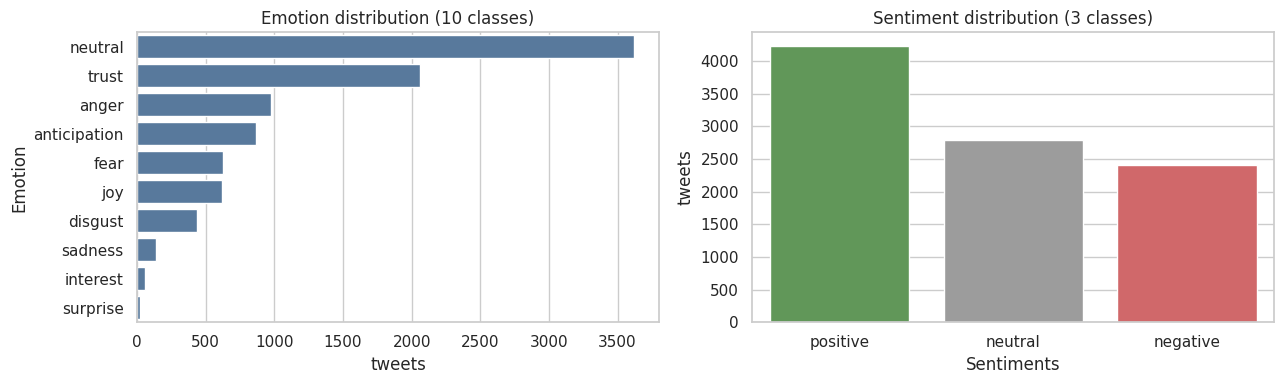

Emotion imbalance (largest/smallest class): 164.5


In [ ]:
df["n_words_clean"] = df["text_clean"].str.split().str.len()
order_e = df[EMOTION_COL].value_counts().index

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, y=EMOTION_COL, order=order_e, color="#4C78A8", ax=ax[0])
ax[0].set_title("Emotion distribution (10 classes)"); ax[0].set_xlabel("tweets")
sns.countplot(data=df, x=SENTIMENT_COL, order=["positive", "neutral", "negative"], hue=SENTIMENT_COL,
              palette={"positive": "#59A14F", "neutral": "#9C9C9C", "negative": "#E15759"}, legend=False, ax=ax[1])
ax[1].set_title("Sentiment distribution (3 classes)"); ax[1].set_ylabel("tweets")
plt.tight_layout(); plt.savefig(f"{FIG}/class_distribution.png", dpi=150); plt.show()

S["emotion_counts"] = df[EMOTION_COL].value_counts().to_dict()
S["sentiment_counts"] = df[SENTIMENT_COL].value_counts().to_dict()
mx, mn = df[EMOTION_COL].value_counts().iloc[[0, -1]]
S["emotion_imbalance_ratio"] = round(float(mx / mn), 1)
print("Emotion imbalance (largest/smallest class):", round(mx / mn, 1))

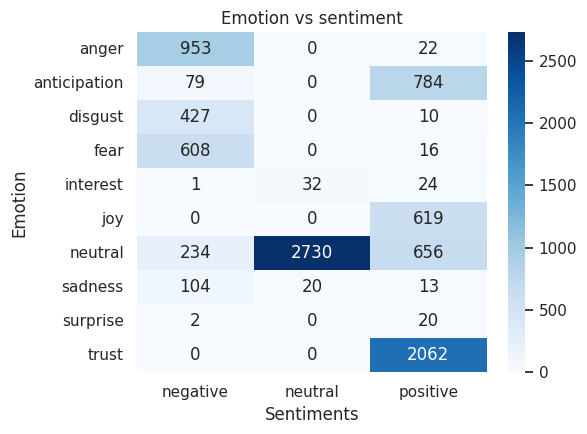

In [ ]:
ct = pd.crosstab(df[EMOTION_COL], df[SENTIMENT_COL])
plt.figure(figsize=(6, 4.5)); sns.heatmap(ct, annot=True, fmt="d", cmap="Blues")
plt.title("Emotion vs sentiment"); plt.tight_layout(); plt.savefig(f"{FIG}/emotion_vs_sentiment.png", dpi=150); plt.show()


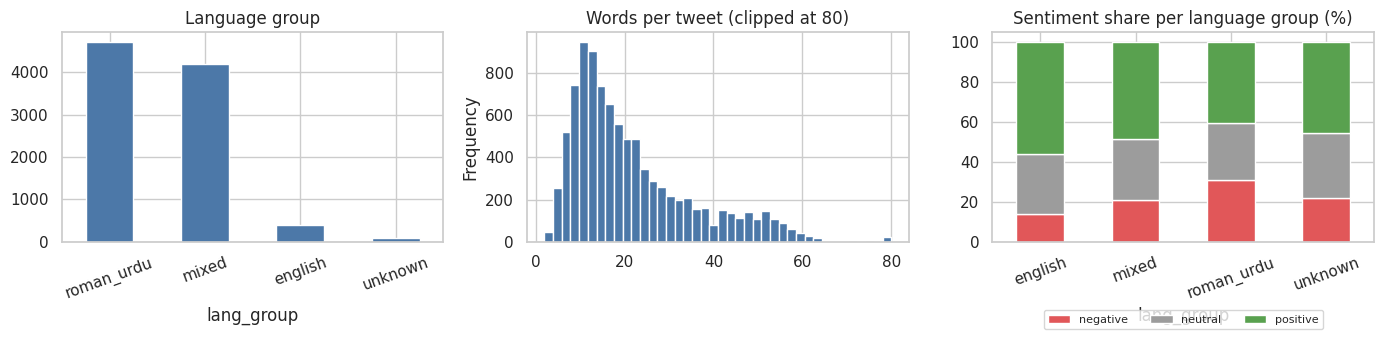

{'neutral': 16.0, 'joy': 16.0, 'anticipation': 17.0, 'trust': 17.0, 'surprise': 18.0, 'sadness': 19.0, 'anger': 21.0, 'disgust': 21.0, 'fear': 22.0, 'interest': 23.0}


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
df["lang_group"].value_counts().plot(kind="bar", ax=ax[0], color="#4C78A8"); ax[0].set_title("Language group"); ax[0].tick_params(axis="x", rotation=20)
df["n_words_clean"].clip(upper=80).plot(kind="hist", bins=40, ax=ax[1], color="#4C78A8"); ax[1].set_title("Words per tweet (clipped at 80)")
(pd.crosstab(df["lang_group"], df[SENTIMENT_COL], normalize="index") * 100).plot(kind="bar", stacked=True, ax=ax[2], color=["#E15759", "#9C9C9C", "#59A14F"])
ax[2].set_title("Sentiment share per language group (%)"); ax[2].tick_params(axis="x", rotation=20); ax[2].legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=3, fontsize=8, title=None)
plt.tight_layout(); plt.savefig(f"{FIG}/language_and_length.png", dpi=150); plt.show()
print(df.groupby(EMOTION_COL)["n_words_clean"].median().sort_values().to_dict())

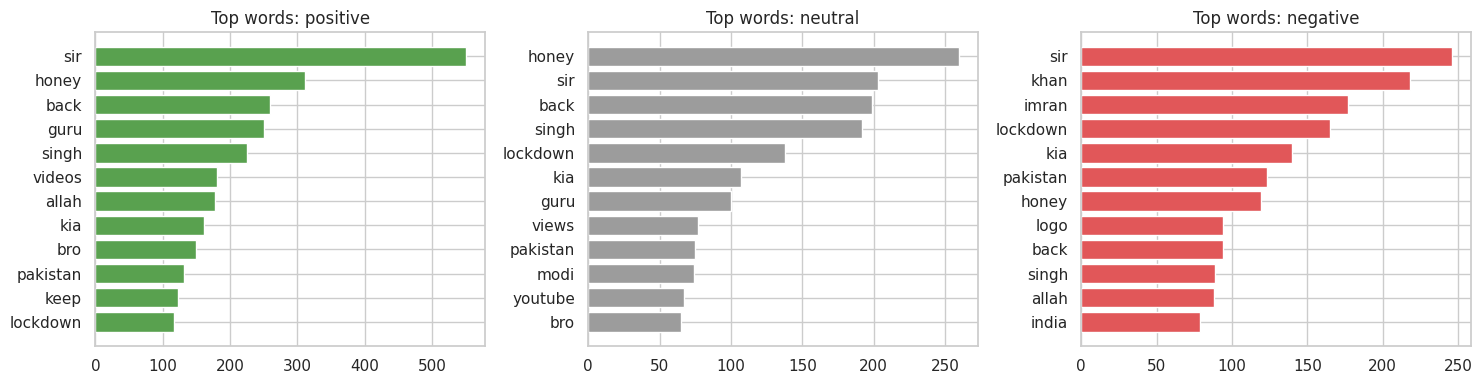

{'positive': ['sir', 'honey', 'back', 'guru', 'singh', 'videos'], 'neutral': ['honey', 'sir', 'back', 'singh', 'lockdown', 'kia'], 'negative': ['sir', 'khan', 'imran', 'lockdown', 'kia', 'pakistan']}


In [ ]:
STOP = EN_WORDS | RU_WORDS | set("is in a to or me be it i he do no all up us ma on at so as by an if am".split())
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
top_words = {}
for a, s, col in zip(ax, ["positive", "neutral", "negative"], ["#59A14F", "#9C9C9C", "#E15759"]):
    cnt = Counter(w for t in df.loc[df[SENTIMENT_COL] == s, "text_clean"] for w in t.split() if w not in STOP and len(w) > 2)
    top = cnt.most_common(12); top_words[s] = top
    a.barh([w for w, _ in top][::-1], [c for _, c in top][::-1], color=col); a.set_title(f"Top words: {s}")
plt.tight_layout(); plt.savefig(f"{FIG}/top_words.png", dpi=150); plt.show()
S["top_words"] = {k: [w for w, _ in v[:6]] for k, v in top_words.items()}
print(S["top_words"])

**Key EDA observations** (numbers are in the final summary at the end)
* Both tasks are imbalanced: `neutral` and `trust` dominate the emotion task, while `surprise`, `interest` and `sadness` have very few tweets.
* `trust`, `joy`, `anticipation` are (almost) always positive and `anger`, `fear`, `disgust` almost always negative, but `neutral` emotion appears under all three sentiments (label noise).
* The most frequent content words (`song`, `honey`, `singh`, `sir`, `bhai`, `lockdown`...) show the corpus is dominated by a few topics (music-video comments, politics, COVID lockdown) and by lexicon trigger words, so models may partly learn topic/keyword shortcuts.
* Only about 4% of tweets are English-only; roughly 45% are clearly code-mixed (Roman Urdu + English markers) and about 50% are mostly Roman Urdu, so English-only preprocessing or models would not be enough. The raw data contains no @mentions, URLs or emoji (already stripped by the authors), but the pipeline handles them for safety; hashtags appear in about 8.5% of tweets.

## 11. Lexicon cleaning and lexicon features
The raw lexicon (Sheet1) has data-entry problems that are fixed first: an empty column (`Unnamed: 4`), stray values (`` `1``, `a`, `Joy` in a numeric column), label typos (`sadness`, `interest`, `Intereset`), mixed float/int/object types, one missing English word.

**Why the original `lex_coverage` was not informative:** it counted *every* word of the lexicon (including neutral entries such as *the, is, ka*), so about 45% of tokens "hit" for every sentiment (0.454 / 0.457 / 0.451). We now index only **emotion/polarity-bearing, single-word entries** and keep per-emotion counts, which can actually be fed to the models.

In [ ]:
lex = lexicon_raw.drop(columns=[c for c in lexicon_raw.columns if str(c).startswith("Unnamed")]).copy()
lex = lex.rename(columns={"English (en)": "en", "urdu (ur)": "ur"})
FLAGS = ["Positive", "Negative", "Anger", "Anticipation", "Disgust", "Fear", "Joy", "Sadness", "Surprise", "Trust", "Interest"]
for c in FLAGS:
    lex[c] = pd.to_numeric(lex[c].astype(str).str.replace("`", "").str.strip(), errors="coerce").fillna(0).astype(int)
lex["Emotions"] = lex["Emotions"].astype(str).str.strip().str.capitalize().replace({"Intereset": "Interest"})
lex = lex.drop(columns=["Priority"])
lex = lex.drop_duplicates(["en", "ur"]).reset_index(drop=True)
lex["has_signal"] = lex[FLAGS].sum(axis=1) > 0
print("Clean lexicon rows:", len(lex), "| entries carrying emotion/polarity:", int(lex.has_signal.sum()))
print(lex["Emotions"].value_counts().to_dict())

STOP_LEX = STOP | {"emo"}
tok_flags = defaultdict(lambda: np.zeros(len(FLAGS), dtype=int))
multiword = 0
for _, r in lex[lex.has_signal].iterrows():
    for col in ["en", "ur"]:
        if pd.isna(r[col]): continue
        toks = full_clean(str(r[col]), NORM_MAP).split()
        if len(toks) != 1:
            multiword += 1; continue
        w = toks[0]
        if len(w) > 2 and w not in STOP_LEX:
            tok_flags[w] = np.maximum(tok_flags[w], r[FLAGS].to_numpy(dtype=int))
print("Single-word lexicon tokens indexed:", len(tok_flags), "| multi-word entries skipped:", multiword)
S.update(lexicon_clean_rows=len(lex), lexicon_signal_rows=int(lex.has_signal.sum()), lexicon_tokens=len(tok_flags))

Clean lexicon rows: 14048 | entries carrying emotion/polarity: 6578
{'Neutral': 9154, 'Anger': 1298, 'Anticipation': 783, 'Trust': 705, 'Fear': 623, 'Disgust': 582, 'Sadness': 362, 'Joy': 326, 'Surprise': 128, 'Interest': 87}
Single-word lexicon tokens indexed: 10067 | multi-word entries skipped: 1583


In [ ]:
LEX_COLS = ["lex_" + c.lower() for c in FLAGS]
def lex_features(text):
    toks = text.split()
    v = np.zeros(len(FLAGS), dtype=int); hits = 0
    for w in toks:
        if w in tok_flags:
            v += tok_flags[w]; hits += 1
    return pd.Series(list(v) + [hits, hits / max(len(toks), 1)], index=LEX_COLS + ["lex_hits", "lex_coverage"])

df[LEX_COLS + ["lex_hits", "lex_coverage"]] = df["text_clean"].apply(lex_features)
print(df[["lex_hits", "lex_coverage"]].describe().round(3))
print("\nMean lexicon features by sentiment:")
print(df.groupby(SENTIMENT_COL)[["lex_positive", "lex_negative", "lex_hits", "lex_coverage"]].mean().round(3))
S["lex_mean_by_sentiment"] = df.groupby(SENTIMENT_COL)[["lex_positive", "lex_negative"]].mean().round(3).to_dict()
S["tweets_zero_lex_hits_pct"] = round(100 * float((df.lex_hits == 0).mean()), 1)

       lex_hits  lex_coverage
count  9416.000      9416.000
mean      1.916         0.092
std       1.889         0.079
min       0.000         0.000
25%       1.000         0.034
50%       1.000         0.083
75%       3.000         0.132
max      39.000         1.000

Mean lexicon features by sentiment:
            lex_positive  lex_negative  lex_hits  lex_coverage
Sentiments                                                    
negative           1.023         0.869     2.260         0.095
neutral            0.905         0.531     1.683         0.086
positive           1.104         0.533     1.873         0.093


**Reading the result:** the signal is modest. `lex_negative` is clearly higher in negative tweets (about 0.87 vs 0.53), but `lex_positive` barely differs between classes, and about 22% of tweets have no lexicon hit at all (the trigger word is literally present in only ~19% of tweets, Section 3). Treat these as *optional* extra features: in Phase 3 compare models **with and without** them (ablation) before claiming they help.

## 12. Stratified train / validation / test split (70 / 15 / 15)
Stratified on `emotion` (the harder, more imbalanced task); sentiment proportions are checked afterwards. Duplicates were removed beforehand, so no tweet text is shared between splits.

In [ ]:
from sklearn.model_selection import train_test_split

counts = df[EMOTION_COL].value_counts()
print(counts.tail(4).to_dict())

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df[EMOTION_COL], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df[EMOTION_COL], random_state=SEED)
print("train:", len(train_df), "val:", len(val_df), "test:", len(test_df))
assert not (set(train_df.text_clean) & set(test_df.text_clean)) and not (set(train_df.text_clean) & set(val_df.text_clean))

for col in [SENTIMENT_COL, EMOTION_COL, "lang_group"]:
    print(f"\n{col}:")
    print(pd.DataFrame({"train": train_df[col].value_counts(normalize=True), "val": val_df[col].value_counts(normalize=True),
                        "test": test_df[col].value_counts(normalize=True)}).round(3))

print("\nRare-class sizes (train/val/test):")
for c in ["surprise", "interest", "sadness"]:
    print(c, (train_df[EMOTION_COL] == c).sum(), (val_df[EMOTION_COL] == c).sum(), (test_df[EMOTION_COL] == c).sum())

tr_vocab = set(w for t in train_df.text_clean for w in t.split())
def oov(d):
    toks = [w for t in d.text_clean for w in t.split()]
    return sum(w not in tr_vocab for w in toks) / len(toks)
print(f"\nOOV rate vs training vocabulary: val {oov(val_df):.1%}, test {oov(test_df):.1%}")
S.update(train=len(train_df), val=len(val_df), test=len(test_df), oov_val=round(oov(val_df), 3), oov_test=round(oov(test_df), 3),
         rare_test={c: int((test_df[EMOTION_COL] == c).sum()) for c in ["surprise", "interest", "sadness"]})

{'disgust': 437, 'sadness': 137, 'interest': 57, 'surprise': 22}
train: 6591 val: 1412 test: 1413

Sentiments:
            train    val   test
Sentiments                     
positive    0.449  0.455  0.440
neutral     0.294  0.293  0.304
negative    0.257  0.252  0.255

Emotion:
              train    val   test
Emotion                          
anger         0.104  0.103  0.103
anticipation  0.092  0.091  0.092
disgust       0.046  0.046  0.047
fear          0.066  0.066  0.067
interest      0.006  0.006  0.006
joy           0.066  0.066  0.066
neutral       0.384  0.385  0.384
sadness       0.015  0.015  0.014
surprise      0.002  0.003  0.002
trust         0.219  0.219  0.219

lang_group:
            train    val   test
lang_group                     
roman_urdu  0.500  0.500  0.502
mixed       0.443  0.459  0.451
english     0.047  0.032  0.036
unknown     0.010  0.009  0.011

Rare-class sizes (train/val/test):
surprise 15 4 3
interest 40 9 8
sadness 96 21 20

OOV rate vs training

**Note on rare classes.** `surprise` and `interest` end up with only a handful of tweets in validation/test, so their per-class scores will be very noisy. In Phase 3/4 we report per-class metrics and macro-F1 with this caveat, and (team decision) may also report a variant with the two smallest classes merged.

## 13. Class imbalance handling and saving outputs
No oversampling before splitting (it would copy tweets into validation/test). Class weights are computed from the **training set only**; macro-F1 is the main metric.

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

meta = {}
for name, col in [("sentiment", SENTIMENT_COL), ("emotion", EMOTION_COL)]:
    classes = sorted(df[col].unique())
    label2id = {l: i for i, l in enumerate(classes)}
    w = compute_class_weight("balanced", classes=np.array(classes), y=train_df[col])
    meta[name] = {"label2id": label2id, "class_weights": dict(zip(classes, w.round(3).tolist()))}
    print(name, meta[name]["class_weights"])

KEEP = ["row_id", TEXT_COL, "text_light", "text_clean", SENTIMENT_COL, EMOTION_COL, "lang_group", "cmi", "n_words_clean"] + LEX_COLS + ["lex_hits", "lex_coverage"]
for split, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    d = d[KEEP].copy()
    d["sentiment_id"] = d[SENTIMENT_COL].map(meta["sentiment"]["label2id"])
    d["emotion_id"] = d[EMOTION_COL].map(meta["emotion"]["label2id"])
    d.to_csv(f"{OUT}/{split}.csv", index=False)

# full file also keeps Mood and the trigger word for ANALYSIS ONLY (never use them as model inputs)
df[KEEP + [MOOD_COL, "lex_word"]].to_csv(f"{OUT}/full_clean.csv", index=False)
lex.drop(columns=["has_signal"]).to_csv(f"{OUT}/lexicon_clean.csv", index=False)
json.dump(meta, open(f"{OUT}/label_meta.json", "w"), indent=2)
json.dump(NORM_MAP, open(f"{OUT}/norm_map.json", "w"), indent=2, ensure_ascii=False)
S["class_weights_emotion"] = meta["emotion"]["class_weights"]
print("Saved:", sorted(os.listdir(OUT)))

sentiment {'negative': 1.299, 'neutral': 1.134, 'positive': 0.742}
emotion {'anger': 0.965, 'anticipation': 1.091, 'disgust': 2.154, 'fear': 1.508, 'interest': 16.478, 'joy': 1.522, 'neutral': 0.26, 'sadness': 6.866, 'surprise': 43.94, 'trust': 0.457}
Saved: ['full_clean.csv', 'label_meta.json', 'lexicon_clean.csv', 'norm_map.json', 'test.csv', 'train.csv', 'val.csv']


## 14. Final dataset summary

In [ ]:
summary_table = pd.DataFrame({
    "stage": ["Raw tweets", "After conflict + duplicate removal", "After cleaned-text dedup (final)", "Train", "Validation", "Test"],
    "tweets": [S["raw_rows"], S["after_raw_dedup"], S["after_clean_dedup"], S["train"], S["val"], S["test"]]})
print(summary_table.to_string(index=False))
print("\nTasks: sentiment (3 classes), emotion (10 classes)  |  Mood: redundant with emotion, not modelled")
print("Columns in train.csv:", pd.read_csv(f"{OUT}/train.csv", nrows=1).columns.tolist())
json.dump(S, open(f"{OUT}/summary.json", "w"), indent=2, default=str)
S

                             stage  tweets
                        Raw tweets    9818
After conflict + duplicate removal    9481
  After cleaned-text dedup (final)    9416
                             Train    6591
                        Validation    1412
                              Test    1413

Tasks: sentiment (3 classes), emotion (10 classes)  |  Mood: redundant with emotion, not modelled
Columns in train.csv: ['row_id', 'Text', 'text_light', 'text_clean', 'Sentiments', 'Emotion', 'lang_group', 'cmi', 'n_words_clean', 'lex_positive', 'lex_negative', 'lex_anger', 'lex_anticipation', 'lex_disgust', 'lex_fear', 'lex_joy', 'lex_sadness', 'lex_surprise', 'lex_trust', 'lex_interest', 'lex_hits', 'lex_coverage', 'sentiment_id', 'emotion_id']


{'raw_rows': 9818,
 'raw_exact_dups': 28,
 'raw_unique_texts': 9626,
 'lexicon_rows_raw': 14048,
 'mood_is_function_of_emotion': True,
 'trigger_purity_emotion': 1.0,
 'trigger_words': 1509,
 'top10_trigger_share': 0.259,
 'bhai_share': 0.098,
 'trigger_in_text': 0.193,
 'neutral_emotion_nonneutral_sentiment': 938,
 'conflict_rows': 296,
 'conflict_texts': 141,
 'after_raw_dedup': 9481,
 'raw_features_pct': {'hashtags': 8.5,
  'mentions': 0.0,
  'urls': 0.0,
  'emoji': 0.0,
  'html_entities': 0.7},
 'words_mean': 21.4,
 'words_median': 17.0,
 'after_clean_dedup': 9416,
 'vocab_before': 28697,
 'vocab_after': 21188,
 'lang_counts': {'roman_urdu': 4713,
  'mixed': 4207,
  'english': 404,
  'unknown': 92},
 'cmi_mean_mixed': 35.0,
 'emotion_counts': {'neutral': 3620,
  'trust': 2062,
  'anger': 975,
  'anticipation': 863,
  'fear': 624,
  'joy': 619,
  'disgust': 437,
  'sadness': 137,
  'interest': 57,
  'surprise': 22},
 'sentiment_counts': {'positive': 4226, 'neutral': 2782, 'negative'